# 01 — Foundations: Why We Sample

**MCMC Zero to Hero — Module 1**

### The problem

In Bayesian inference we want the **posterior distribution**

$$ p(\theta \mid x) = \frac{p(x \mid \theta)\, p(\theta)}{p(x)}, \qquad p(x) = \int p(x\mid\theta)\,p(\theta)\, d\theta. $$

The denominator $p(x)$ (the *evidence*) is an integral that is intractable in all but toy
problems — especially once $\theta$ has more than 2–3 dimensions. We almost never need $p(x)$
itself; what we need are **expectations under the posterior**:

$$ \mathbb{E}_{p(\theta\mid x)}[f(\theta)] = \int f(\theta)\, p(\theta\mid x)\, d\theta. $$

Monte Carlo methods estimate such integrals by drawing samples $\theta^{(1)}, \dots, \theta^{(N)}$
from $p(\theta \mid x)$ and using

$$ \mathbb{E}[f(\theta)] \approx \frac{1}{N}\sum_{i=1}^N f(\theta^{(i)}). $$

The catch: *how do you sample from a distribution you can only evaluate up to an unknown
normalising constant?* That is exactly the problem **Markov Chain Monte Carlo (MCMC)** solves,
and it's what this course builds up to from first principles. This module covers the classical
(non-Markov-chain) Monte Carlo tools first, so you can see clearly *why* they break down and
*why* MCMC is needed.

**Roadmap of the course**

| # | Notebook | Topic |
|---|----------|-------|
| 01 | Foundations | Monte Carlo integration, inverse-CDF, rejection, importance sampling |
| 02 | Markov chains | Stationarity, detailed balance, ergodicity |
| 03 | Metropolis–Hastings | The core algorithm, derived and coded from scratch |
| 04 | Random-Walk Metropolis | Real case study, tuning, multivariate targets |
| 05 | Gibbs sampling | Conditional sampling, conjugate Bayesian regression |
| 06 | Diagnostics | Trace plots, autocorrelation, ESS, $\hat R$ |
| 07 | HMC, emcee & capstone | Hamiltonian Monte Carlo, ensemble samplers, a full Bayesian logistic regression project |

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
rng = np.random.default_rng(42)

## 1. Monte Carlo integration

The law of large numbers says the sample average converges to the true expectation. Let's
verify this on a case where we *know* the answer: $\mathbb{E}[X^2]$ for $X \sim \mathcal N(0,1)$
is $1$.

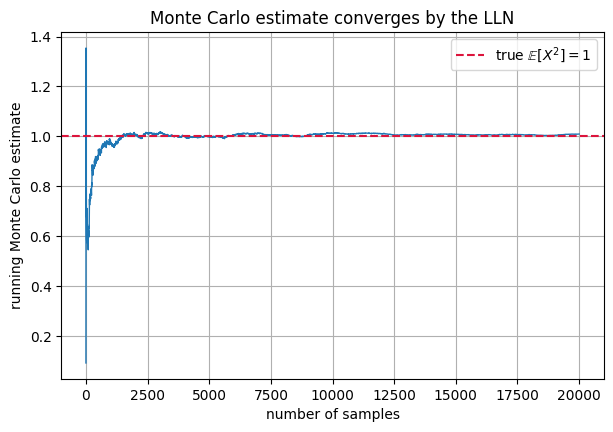

Estimate with N=20000 samples: 1.0095


In [3]:
def running_mc_estimate(f, sampler, n_max=20000, rng=rng):
    samples = sampler(n_max)
    print(f"samples {samples}")
    values = f(samples)
    print(f"values {values}")
    cumulative_mean = np.cumsum(values) / np.arange(1, n_max + 1)
    print(f"cumulative_mean {cumulative_mean}")
    return cumulative_mean

f = lambda x: x ** 2
sampler = lambda n: rng.normal(size=n)

estimate = running_mc_estimate(f, sampler)

plt.plot(estimate, lw=1)
plt.axhline(1.0, color="crimson", ls="--", label=r"true $\mathbb{E}[X^2]=1$")
plt.xlabel("number of samples")
plt.ylabel("running Monte Carlo estimate")
plt.title("Monte Carlo estimate converges by the LLN")
plt.legend()
plt.show()

print(f"Estimate with N=20000 samples: {estimate[-1]:.4f}")

The Monte Carlo standard error shrinks as $O(1/\sqrt N)$ **regardless of dimension** — this is
the whole reason Monte Carlo beats quadrature grids in high dimensions (grids scale as
$O(h^{-d})$). The catch is that so far we assumed we could *already* draw i.i.d. samples from
the target. In Bayesian inference, we usually can't.

## 2. Inverse transform sampling

If we know the target's CDF $F$ in closed form and can invert it, sampling is trivial:
$U \sim \text{Unif}(0,1) \Rightarrow F^{-1}(U) \sim F$.

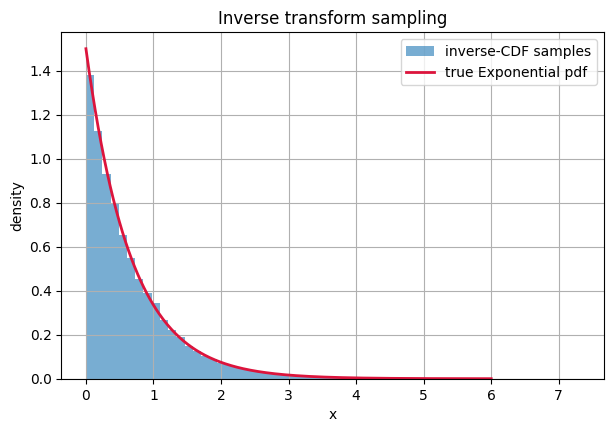

In [4]:
# Sample from an Exponential(lambda) via inverse-CDF: F^{-1}(u) = -ln(1-u)/lambda
lam = 1.5
u = rng.uniform(size=20000)
x = -np.log(1 - u) / lam

grid = np.linspace(0, 6, 400)
plt.hist(x, bins=60, density=True, alpha=0.6, label="inverse-CDF samples")
plt.plot(grid, lam * np.exp(-lam * grid), color="crimson", lw=2, label="true Exponential pdf")
plt.legend(); plt.title("Inverse transform sampling"); plt.xlabel("x"); plt.ylabel("density")
plt.show()

This is elegant but only works when $F^{-1}$ is available analytically — true for a handful of
named distributions, essentially never true for an arbitrary Bayesian posterior.

## 3. Rejection sampling

We can sample from an *unnormalised* target $p(\theta) = \tilde p(\theta)/Z$ (where $Z$ is
unknown) using only a proposal $q$ we *can* sample from, provided we can find $M$ with
$\tilde p(\theta) \le M\, q(\theta)$ for all $\theta$:

1. Draw $\theta \sim q$.
2. Draw $u \sim \text{Unif}(0,1)$.
3. Accept $\theta$ if $u \le \dfrac{\tilde p(\theta)}{M\, q(\theta)}$, else reject and repeat.

Crucially this needs *no normalising constant* for $p$ — a first step toward the MCMC idea.
Let's sample from a bimodal mixture-of-Gaussians target using a wide Gaussian proposal.

Acceptance rate: 29.0%


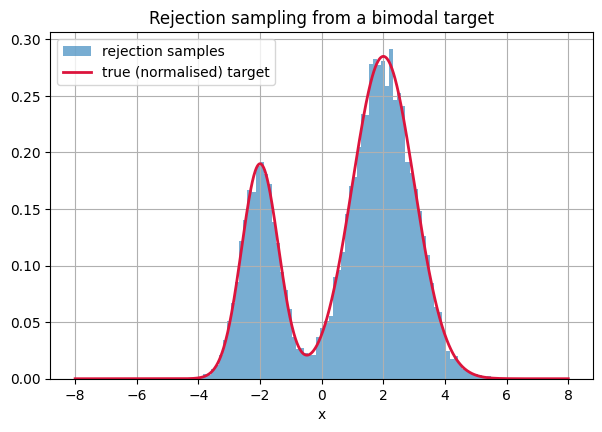

In [5]:
# Unnormalised bimodal target: mixture of two Gaussians (weights need not sum to 1 for
# rejection sampling to work -- only the *shape* matters).
def target_unnorm(x):
    return 0.4 * np.exp(-0.5 * ((x + 2) / 0.6) ** 2) + 0.6 * np.exp(-0.5 * ((x - 2) / 1.0) ** 2)

proposal_std = 4.0
grid = np.linspace(-8, 8, 1000)
M = np.max(target_unnorm(grid) / (np.exp(-0.5 * (grid / proposal_std) ** 2) / (proposal_std * np.sqrt(2 * np.pi)))) * 1.05

def rejection_sample(n, rng=rng):
    accepted = []
    n_proposed = 0
    while len(accepted) < n:
        x = rng.normal(0, proposal_std)
        n_proposed += 1
        q_x = np.exp(-0.5 * (x / proposal_std) ** 2) / (proposal_std * np.sqrt(2 * np.pi))
        u = rng.uniform()
        if u <= target_unnorm(x) / (M * q_x):
            accepted.append(x)
    return np.array(accepted), n_proposed

samples, n_proposed = rejection_sample(20000)
print(f"Acceptance rate: {len(samples)/n_proposed:.1%}")

plt.hist(samples, bins=80, density=True, alpha=0.6, label="rejection samples")
Z = np.trapezoid(target_unnorm(grid), grid)
plt.plot(grid, target_unnorm(grid) / Z, color="crimson", lw=2, label="true (normalised) target")
plt.legend(); plt.title("Rejection sampling from a bimodal target"); plt.xlabel("x")
plt.show()

Rejection sampling works, but the acceptance rate collapses as dimension grows (the "curse of
dimensionality") because a bounding envelope $Mq(\theta)$ has to dominate the target
*everywhere*, and the volume where $q$ and $p$ actually overlap shrinks exponentially. It is
almost never usable beyond a handful of dimensions.

## 4. Importance sampling

Instead of accepting/rejecting, keep *every* proposal sample but re-weight it:

$$ \mathbb{E}_p[f(\theta)] = \int f(\theta) \frac{p(\theta)}{q(\theta)} q(\theta)\, d\theta
   \approx \frac{1}{N}\sum_i f(\theta^{(i)})\, w(\theta^{(i)}), \quad
   w(\theta^{(i)}) = \frac{\tilde p(\theta^{(i)})}{q(\theta^{(i)})}\Big/ \sum_j \tilde p(\theta^{(j)})/q(\theta^{(j)}) .$$

No accept/reject step, no normalising constant needed for $p$, but if $q$ is a poor match for
$p$ a handful of samples get huge weights and the effective sample size collapses.

Effective sample size out of 20000 draws: 9451  (47.3%)
Importance-sampling estimate of E[theta]: 0.879


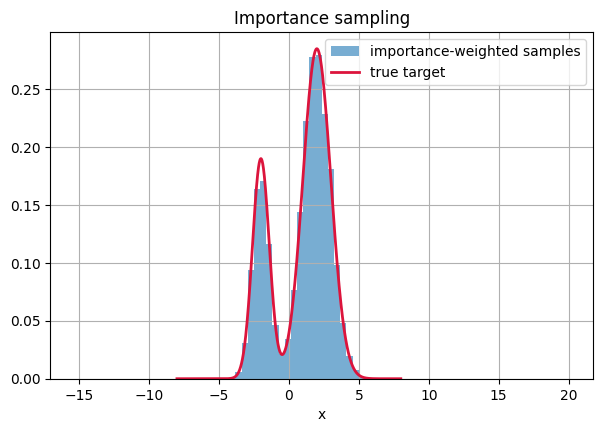

In [6]:
def q_pdf(x):
    return np.exp(-0.5 * (x / proposal_std) ** 2) / (proposal_std * np.sqrt(2 * np.pi))

x_is = rng.normal(0, proposal_std, size=20000)
raw_w = target_unnorm(x_is) / q_pdf(x_is)
w = raw_w / raw_w.sum()

# effective sample size (Kish's ESS)
ess = 1.0 / np.sum(w ** 2)
print(f"Effective sample size out of 20000 draws: {ess:.0f}  ({ess/20000:.1%})")

mean_estimate = np.sum(w * x_is)
print(f"Importance-sampling estimate of E[theta]: {mean_estimate:.3f}")

plt.hist(x_is, bins=80, weights=w, density=True, alpha=0.6, label="importance-weighted samples")
plt.plot(grid, target_unnorm(grid) / Z, color="crimson", lw=2, label="true target")
plt.legend(); plt.title("Importance sampling"); plt.xlabel("x")
plt.show()

## 5. Why these all fail us eventually

Rejection and importance sampling both need a **global proposal $q$** that resembles the
target everywhere. In a Bayesian posterior with, say, 20 correlated parameters, designing such
a $q$ is essentially as hard as the original problem.

**The MCMC idea (previewed):** instead of proposing draws independently from a fixed global
$q$, construct a **Markov chain** whose *next* state depends only on the *current* state, and
design its transition rule so that the chain's stationary distribution is exactly our target
$p(\theta\mid x)$ — using only the unnormalised density $\tilde p$. Local proposals (a small
step from the current point) are then enough, because we don't need to cover the whole space
at once, just to *diffuse* through it correctly over many steps.

That requires understanding Markov chains and stationary distributions first — the subject of
Notebook 02.